# CPU and MPS loader batching benchmark

Compare fetching individual rows with `__getitem__` against fetching whole batches with `__getitems__`. Both use the same tensors and `dict_collate_fn`: the first path stacks rows, while the second returns the batch directly.

We time complete passes through the loader on CPU and MPS, excluding data preparation and model fitting.

In [1]:
from pathlib import Path
from time import perf_counter
import platform
import sys

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader, Dataset

# Import this checkout from either the repository root or examples/.
ROOT = Path.cwd() if (Path.cwd() / "scdesigner/src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "scdesigner/src"))
from scdesigner.data.loader import adata_loader, dict_collate_fn

SEED = 42
N_CELLS, N_GENES = 10000, 2000
BATCH_SIZES = [128, 512, 1024, 2048]
REPEATS = 5
DEVICES = ["cpu", "mps"]
FORMULAS = {"mean": "~ group + covariate", "dispersion": "~ 1"}

print(f"Python {platform.python_version()} | PyTorch {torch.__version__}")
print(f"{platform.platform()} | Devices: {DEVICES} | CPU threads: {torch.get_num_threads()}")

Python 3.11.8 | PyTorch 2.6.0.dev20241112
macOS-26.5.2-arm64-arm-64bit | Devices: ['cpu', 'mps'] | CPU threads: 4


In [2]:
rng = np.random.default_rng(SEED)
adata = ad.AnnData(
    X=rng.poisson(1.0, size=(N_CELLS, N_GENES)).astype(np.float32),
    obs=pd.DataFrame(
        {"group": pd.Categorical(rng.choice(["A", "B", "C"], N_CELLS)),
         "covariate": rng.normal(size=N_CELLS)},
        index=[f"cell_{i}" for i in range(N_CELLS)],
    ),
)
# Reuse the same row order in every pass; permutation generation is not timed.
ORDERS = {
    "sequential": list(range(N_CELLS)),
    "shuffled": np.random.default_rng(SEED).permutation(N_CELLS).tolist(),
}
print(f"Data: {adata.n_obs:,} cells × {adata.n_vars:,} genes (float32)")

Data: 10,000 cells × 2,000 genes (float32)


## Timing helpers

The wrapper exposes only `__getitem__`, reusing the original dataset's tensors. MPS synchronization makes the timer wait for GPU work to finish.

In [3]:
class RowDataset(Dataset):
    def __init__(self, dataset):
        self.dataset = dataset

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, index):
        return self.dataset[index]


def time_pass(loader, device):
    if device == "mps":
        torch.mps.synchronize()
    start = perf_counter()
    for _ in loader:
        pass
    if device == "mps":
        torch.mps.synchronize()
    return perf_counter() - start

## Run the experiment

For each device, sampling order, and batch size, benchmark one method at a time: warm up once, then time five passes. Both methods use the same row indices.

In [4]:
measurements = []
for device in DEVICES:
    dataset = adata_loader(adata, FORMULAS, device=device).dataset
    methods = {"__getitem__": RowDataset(dataset), "__getitems__": dataset}

    for order, indices in ORDERS.items():
        for batch_size in BATCH_SIZES:
            for method, data in methods.items():
                loader = DataLoader(
                    data, batch_size=batch_size, sampler=indices, collate_fn=dict_collate_fn
                )
                time_pass(loader, device)  # Warm-up.

                for _ in range(REPEATS):
                    seconds = time_pass(loader, device)
                    measurements.append({
                        "device": device,
                        "order": order,
                        "batch_size": batch_size,
                        "method": method,
                        "seconds": seconds,
                    })

timings = pd.DataFrame(measurements)

In [5]:
# Median seconds per complete pass, and the ratio of old to new time.
results = timings.pivot_table(
    index=["device", "order", "batch_size"], columns="method", values="seconds", aggfunc="median"
)
results["speedup"] = results["__getitem__"] / results["__getitems__"]
results.round(4)

method                        __getitem__  __getitems__  speedup
device order      batch_size                                    
cpu    sequential 128              0.0235        0.0034   6.9943
                  512              0.0270        0.0037   7.2286
                  1024             0.0288        0.0041   7.0410
                  2048             0.0286        0.0029   9.7850
       shuffled   128              0.0265        0.0041   6.5339
                  512              0.0323        0.0067   4.8117
                  1024             0.0331        0.0068   4.8905
                  2048             0.0314        0.0047   6.7467
mps    sequential 128              0.1679        0.0426   3.9380
                  512              0.1675        0.0238   7.0383
                  1024             0.1738        0.0183   9.4989
                  2048             0.1937        0.0156  12.4487
       shuffled   128              0.1694        0.0410   4.1356
                  512              0.1819        0.0201   9.0719
                  1024             0.1633        0.0193   8.4766
                  2048             0.1980        0.0158  12.5664

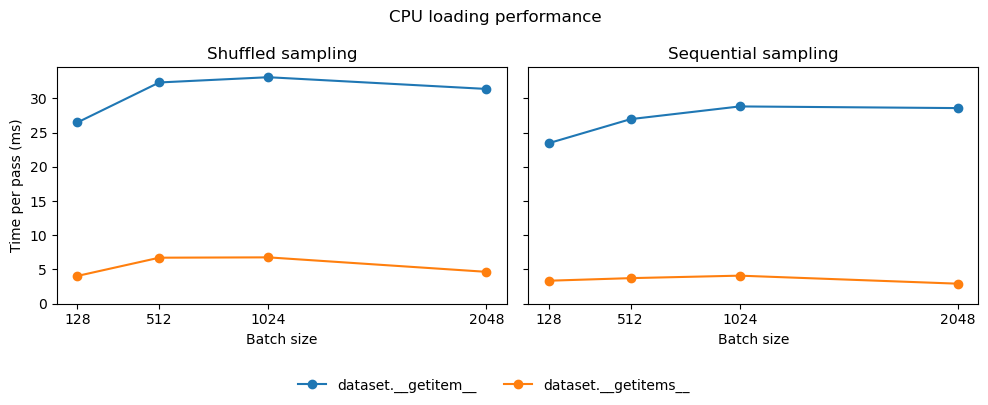

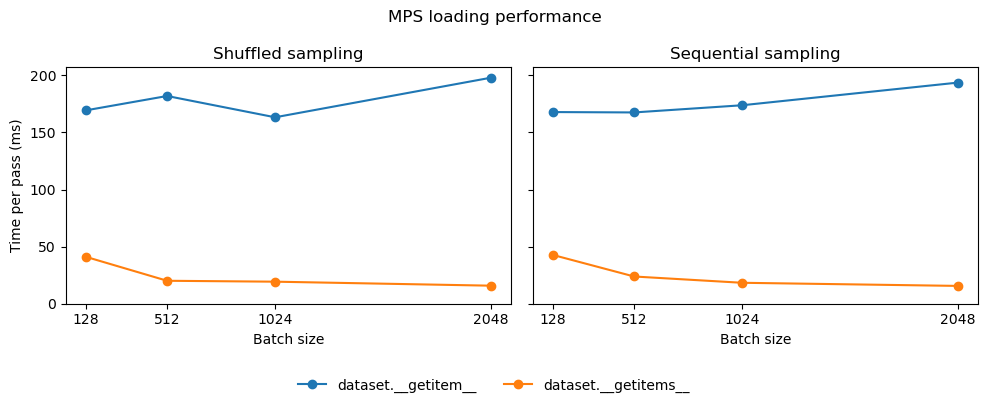

In [6]:
colors = {"__getitem__": "tab:blue", "__getitems__": "tab:orange"}
for device in DEVICES:
    fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
    for ax, order in zip(axes, ["shuffled", "sequential"]):
        values = results.loc[(device, order)]
        for method, color in colors.items():
            ax.plot(values.index, 1000 * values[method], marker="o", color=color,
                    label=f"dataset.{method}")
        ax.set(title=f"{order.capitalize()} sampling", xlabel="Batch size", ylim=(0, None))
        ax.set_xticks(BATCH_SIZES, labels=BATCH_SIZES)
    axes[0].set_ylabel("Time per pass (ms)")
    fig.suptitle(f"{device.upper()} loading performance")
    fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=2, frameon=False)
    fig.tight_layout(rect=(0, 0.1, 1, 1))
    plt.show()